In [2]:
from datasets import load_dataset
import math

In [3]:


ds = load_dataset("avsolatorio/mteb-emotion-avs_triplets")
print(ds)
print(ds["train"][0]) 

df = ds["train"].to_pandas()

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text', 'idx', 'query_idx', 'positive_idx', 'negative_idx'],
        num_rows: 16000
    })
})
{'text': 'i just don t feel i have it in me to get out of bed i can will the dull throbbing of hopelessness to give way and let forth a renewed sensed of hope reflect back on my accomplishments and dig up the inner strength i ve worked so very hard to reestablish', 'label': 0, 'label_text': 'sadness', 'idx': 0, 'query_idx': 0, 'positive_idx': 8206, 'negative_idx': 8560}


In [4]:
word_counts = df['text'].str.split(expand=True).stack().value_counts()

In [5]:
word_counts.head(10)  # Display the top 10 most common words

i          25859
feel       11183
and         9589
to          8972
the         8370
a           6200
that        5112
feeling     5112
of          4990
my          4283
Name: count, dtype: int64

In [6]:
label_counts = df['label'].value_counts()
print(label_counts) 

label
1    5362
0    4666
3    2159
4    1937
2    1304
5     572
Name: count, dtype: int64


In [ ]:
split = ds["train"].train_test_split(test_size=0.2, seed=42)
train_ds, test_ds = split["train"], split["test"]

train_label_counts = dict()
freq_p_class = dict()
for sample in train_ds:
    label = sample["label"]
    train_label_counts[label] = train_label_counts.get(label, 0) + 1
    for word in sample["text"].split():
        if word not in freq_p_class:
            freq_p_class[word] = dict()
        freq_p_class[word][label] = freq_p_class[word].get(label, 0) + 1

v = len(freq_p_class)
total_words = {l: 0 for l in train_label_counts}
for counts in freq_p_class.values():
    for l, c in counts.items():
        total_words[l] += c

In [ ]:
def get_score(text, label):
    score = math.log(train_label_counts[label] / len(train_ds))
    for word in text.split():
        if word not in freq_p_class:
            continue
        score += math.log((freq_p_class[word].get(label, 0) + 1) / (total_words[label] + v))
    return score


def predict(text):
    return max(train_label_counts, key=lambda l: get_score(text, l))

In [9]:
preds = [predict(s["text"]) for s in test_ds]
golds = test_ds["label"]

accuracy = sum(p == g for p, g in zip(preds, golds)) / len(golds)
print(f"accuracy: {accuracy:.4f}")

f1s = []
for l in sorted(train_label_counts):
    tp = sum(p == l and g == l for p, g in zip(preds, golds))
    fp = sum(p == l and g != l for p, g in zip(preds, golds))
    fn = sum(p != l and g == l for p, g in zip(preds, golds))
    f1 = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
    f1s.append(f1)
    print(f"class {l}: f1 {f1:.4f}")
print(f"macro-f1: {sum(f1s) / len(f1s):.4f}")

accuracy: 0.7266
class 0: f1 0.8062
class 1: f1 0.7931
class 2: f1 0.2952
class 3: f1 0.6616
class 4: f1 0.6324
class 5: f1 0.0163
macro-f1: 0.5341


In [12]:
import numpy as np


def confusion_matrix_np(y_true, y_pred, n_classes):
    # rows = true class, cols = predicted class
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (np.asarray(y_true), np.asarray(y_pred)), 1)
    return cm


def metrics_from_cm(cm):
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    precision = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    return precision, recall, f1


n_classes = len(train_label_counts)
cm = confusion_matrix_np(golds, preds, n_classes)
precision, recall, f1 = metrics_from_cm(cm)

print("confusion matrix:\n", cm)
for l in range(n_classes):
    print(f"class {l}: precision {precision[l]:.4f} recall {recall[l]:.4f} f1 {f1[l]:.4f}")
print(f"macro: precision {precision.mean():.4f} recall {recall.mean():.4f} f1 {f1.mean():.4f}")

confusion matrix:
 [[863  58   2   5   4   0]
 [ 42 985   3   4   1   0]
 [ 57 166  49   4   1   0]
 [103  79   0 218   8   0]
 [105  96   0  16 209   0]
 [ 39  65   1   4  12   1]]
class 0: precision 0.7138 recall 0.9260 f1 0.8062
class 1: precision 0.6798 recall 0.9517 f1 0.7931
class 2: precision 0.8909 recall 0.1769 f1 0.2952
class 3: precision 0.8685 recall 0.5343 f1 0.6616
class 4: precision 0.8894 recall 0.4906 f1 0.6324
class 5: precision 1.0000 recall 0.0082 f1 0.0163
macro: precision 0.8404 recall 0.5146 f1 0.5341


In [13]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

sk_cm = confusion_matrix(golds, preds, labels=range(n_classes))
print("confusion matrix match:", np.array_equal(cm, sk_cm))

for name, mine, fn in [("precision", precision, precision_score),
                       ("recall", recall, recall_score),
                       ("f1", f1, f1_score)]:
    sk_per_class = fn(golds, preds, labels=range(n_classes), average=None, zero_division=0)
    sk_macro = fn(golds, preds, labels=range(n_classes), average="macro", zero_division=0)
    print(f"{name}: per-class match {np.allclose(mine, sk_per_class)}, "
          f"macro mine {mine.mean():.4f} vs sklearn {sk_macro:.4f}")

confusion matrix match: True
precision: per-class match True, macro mine 0.8404 vs sklearn 0.8404
recall: per-class match True, macro mine 0.5146 vs sklearn 0.5146
f1: per-class match True, macro mine 0.5341 vs sklearn 0.5341


## Scratch vs scikit-learn Naive Bayes

In [14]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

# token_pattern r"\S+" matches str.split() so both models see the same tokens
vectorizer = CountVectorizer(token_pattern=r"\S+")
X_train = vectorizer.fit_transform(train_ds["text"])
X_test = vectorizer.transform(test_ds["text"])

sk_nb = MultinomialNB(alpha=1.0)  # alpha=1 = Laplace smoothing, same as scratch
sk_nb.fit(X_train, train_ds["label"])
sk_preds = sk_nb.predict(X_test)

sk_nb_cm = confusion_matrix(golds, sk_preds, labels=range(n_classes))
sk_p, sk_r, sk_f = metrics_from_cm(sk_nb_cm)

print(f"scratch accuracy: {accuracy:.4f}")
print(f"sklearn accuracy: {np.mean(sk_preds == np.array(golds)):.4f}")
print(f"prediction agreement: {np.mean(np.array(preds) == sk_preds):.4f}")

scratch accuracy: 0.7266
sklearn accuracy: 0.7266
prediction agreement: 1.0000


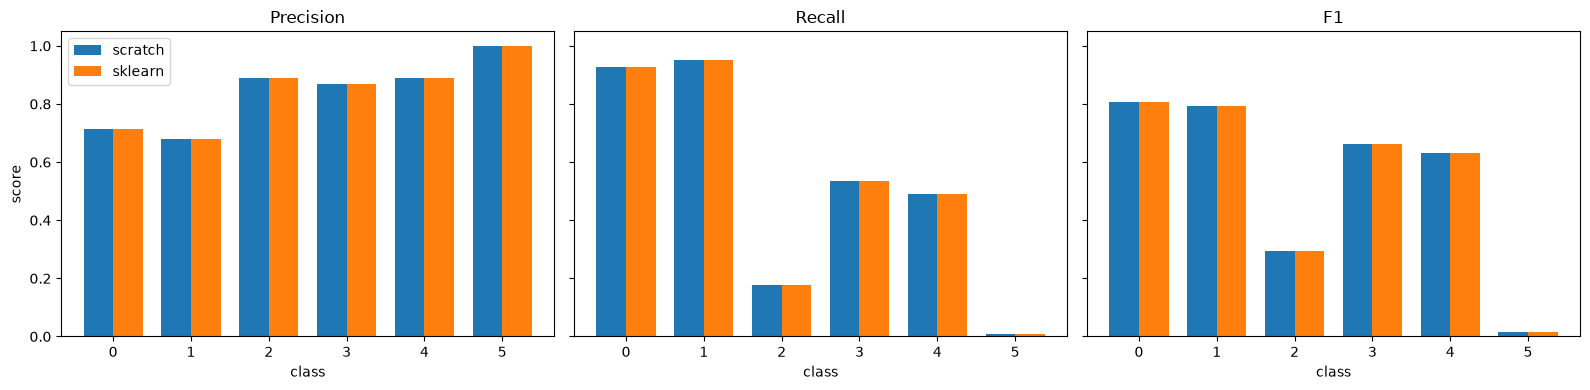

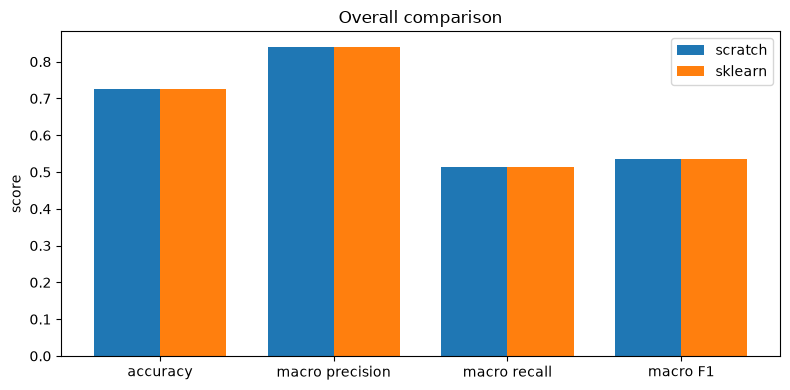

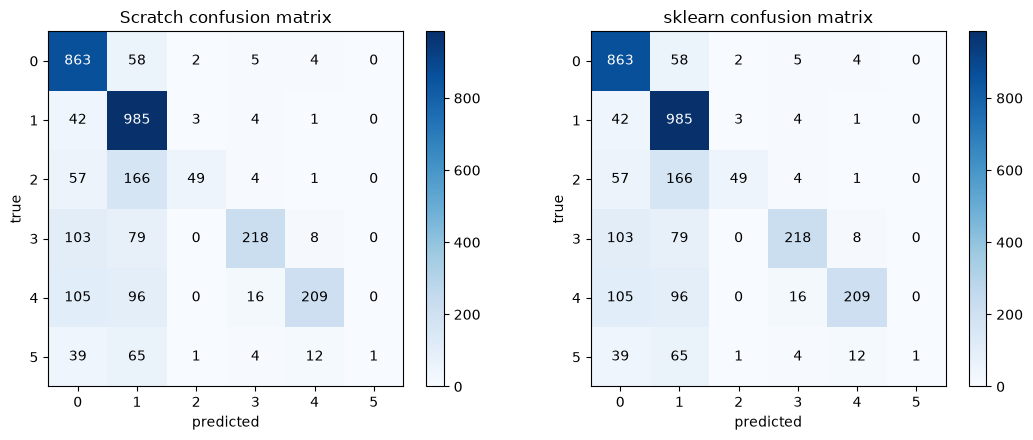

In [15]:
import matplotlib.pyplot as plt

classes = np.arange(n_classes)
width = 0.38

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name, mine, theirs in [(axes[0], "Precision", precision, sk_p),
                               (axes[1], "Recall", recall, sk_r),
                               (axes[2], "F1", f1, sk_f)]:
    ax.bar(classes - width / 2, mine, width, label="scratch")
    ax.bar(classes + width / 2, theirs, width, label="sklearn")
    ax.set_title(name)
    ax.set_xlabel("class")
    ax.set_xticks(classes)
axes[0].set_ylabel("score")
axes[0].legend()
plt.tight_layout()
plt.show()

# overall: accuracy + macro metrics
labels = ["accuracy", "macro precision", "macro recall", "macro F1"]
scratch_vals = [accuracy, precision.mean(), recall.mean(), f1.mean()]
sklearn_vals = [np.mean(sk_preds == np.array(golds)), sk_p.mean(), sk_r.mean(), sk_f.mean()]
x = np.arange(len(labels))
plt.figure(figsize=(8, 4))
plt.bar(x - width / 2, scratch_vals, width, label="scratch")
plt.bar(x + width / 2, sklearn_vals, width, label="sklearn")
plt.xticks(x, labels)
plt.ylabel("score")
plt.title("Overall comparison")
plt.legend()
plt.tight_layout()
plt.show()

# confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, m, title in [(axes[0], cm, "Scratch"), (axes[1], sk_nb_cm, "sklearn")]:
    im = ax.imshow(m, cmap="Blues")
    ax.set_title(f"{title} confusion matrix")
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_xticks(classes)
    ax.set_yticks(classes)
    for i in range(n_classes):
        for j in range(n_classes):
            ax.text(j, i, m[i, j], ha="center", va="center",
                    color="white" if m[i, j] > m.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()